In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/alzheimers_disease_data.csv")
df.head()

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,0,0,1.725883,0,0,0,1,0,0,XXXConfid
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,0,0,2.592424,0,0,0,0,1,0,XXXConfid
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,0,0,7.119548,0,1,0,1,0,0,XXXConfid
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,0,1,6.481226,0,0,0,0,0,0,XXXConfid
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,0,0,0.014691,0,0,1,1,0,0,XXXConfid


In [2]:
print("Rows and columns:", df.shape)
df.info()
df.describe()
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df["Diagnosis"].value_counts())
print(df["Diagnosis"].value_counts(normalize=True) * 100)

Rows and columns: (2149, 35)
<class 'pandas.DataFrame'>
RangeIndex: 2149 entries, 0 to 2148
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PatientID                  2149 non-null   int64  
 1   Age                        2149 non-null   int64  
 2   Gender                     2149 non-null   int64  
 3   Ethnicity                  2149 non-null   int64  
 4   EducationLevel             2149 non-null   int64  
 5   BMI                        2149 non-null   float64
 6   Smoking                    2149 non-null   int64  
 7   AlcoholConsumption         2149 non-null   float64
 8   PhysicalActivity           2149 non-null   float64
 9   DietQuality                2149 non-null   float64
 10  SleepQuality               2149 non-null   float64
 11  FamilyHistoryAlzheimers    2149 non-null   int64  
 12  CardiovascularDisease      2149 non-null   int64  
 13  Diabetes                   214

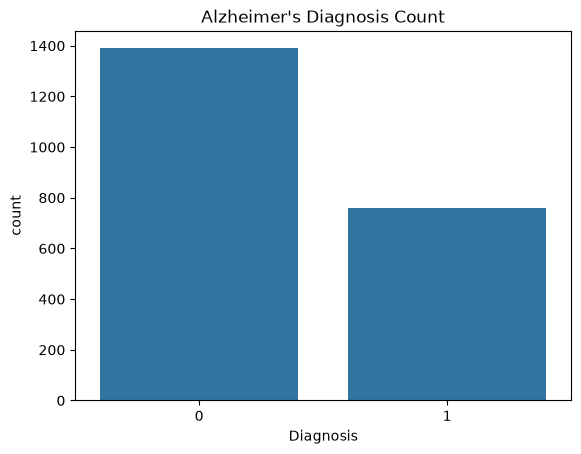

In [3]:
# Chart 1: how many patients in each class
sns.countplot(x="Diagnosis", data=df)
plt.title("Alzheimer's Diagnosis Count")
plt.show()

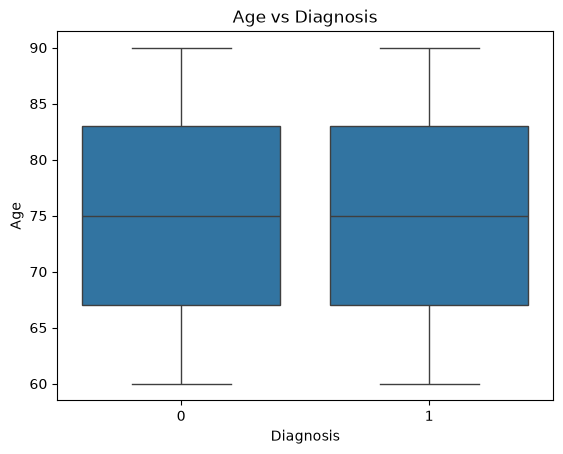

In [4]:
# Chart 2: age compared with diagnosis
sns.boxplot(x="Diagnosis", y="Age", data=df)
plt.title("Age vs Diagnosis")
plt.show()

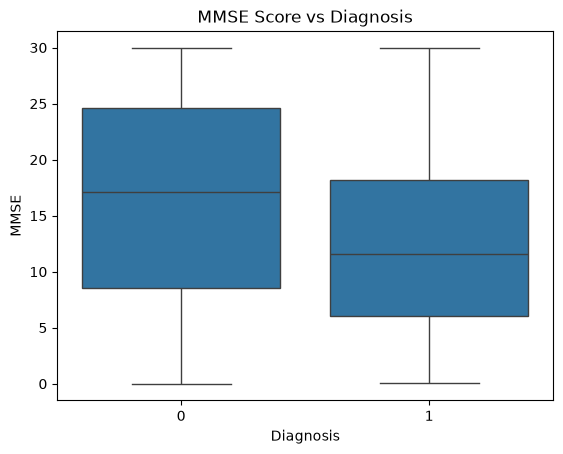

In [5]:
# Chart 3: memory test score compared with diagnosis
sns.boxplot(x="Diagnosis", y="MMSE", data=df)
plt.title("MMSE Score vs Diagnosis")
plt.show()

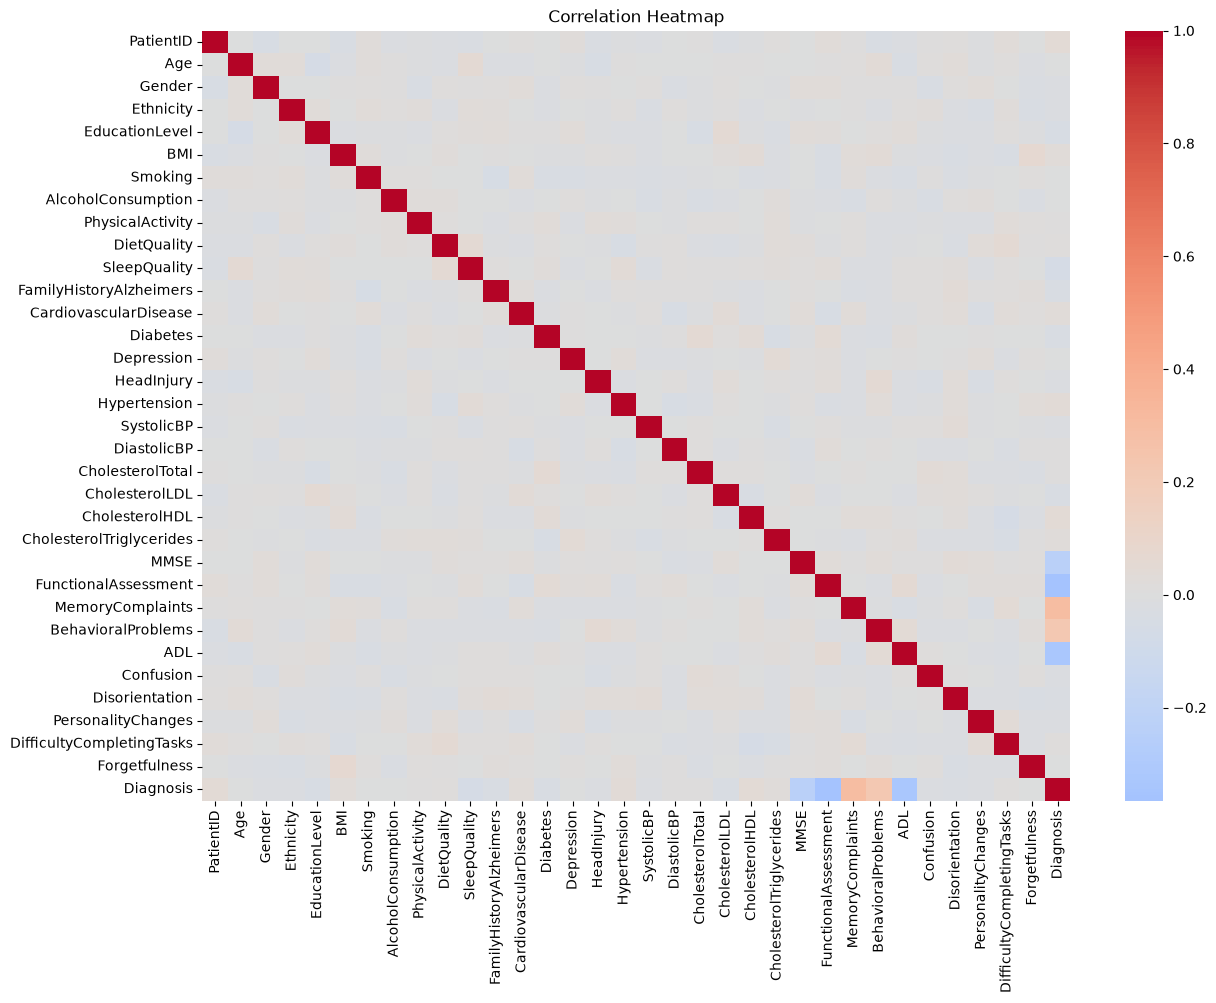

In [6]:
# Chart 4: correlation heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

In [7]:
# Which features relate most to Diagnosis
print(df.corr(numeric_only=True)["Diagnosis"].sort_values(ascending=False))

Diagnosis                    1.000000
MemoryComplaints             0.306742
BehavioralProblems           0.224350
CholesterolHDL               0.042584
PatientID                    0.041019
Hypertension                 0.035080
CardiovascularDisease        0.031490
BMI                          0.026343
CholesterolTriglycerides     0.022672
DifficultyCompletingTasks    0.009069
DietQuality                  0.008506
CholesterolTotal             0.006394
PhysicalActivity             0.005945
DiastolicBP                  0.005293
Forgetfulness               -0.000354
Smoking                     -0.004865
Age                         -0.005488
Depression                  -0.005893
AlcoholConsumption          -0.007618
Ethnicity                   -0.014782
SystolicBP                  -0.015615
Confusion                   -0.019186
PersonalityChanges          -0.020627
Gender                      -0.020975
HeadInjury                  -0.021411
Disorientation              -0.024648
Diabetes    

In [8]:
df = df.drop(columns=["PatientID", "DoctorInCharge"], errors="ignore")
print(df.shape)

(2149, 33)


In [9]:
df = df.drop_duplicates()
df = df.fillna(df.median(numeric_only=True))
print("Missing values left:", df.isnull().sum().sum())
print("Rows:", df.shape[0])

Missing values left: 0
Rows: 2149


In [10]:
df = df.drop(columns=["PatientID", "DoctorInCharge"], errors="ignore")
print(df.shape)

(2149, 33)


In [11]:
df = df.drop_duplicates()
df = df.fillna(df.median(numeric_only=True))
print("Missing values left:", df.isnull().sum().sum())
print("Rows:", df.shape[0])

Missing values left: 0
Rows: 2149


In [12]:
print(df.dtypes.value_counts())

int64      21
float64    12
Name: count, dtype: int64


In [13]:
print(df.select_dtypes(include="object").columns)


Index([], dtype='str')


In [14]:
X = df.drop("Diagnosis", axis=1)
y = df["Diagnosis"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2149, 32)
y shape: (2149,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 1719
Testing rows: 430


In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # learn from training data only
X_test_s = scaler.transform(X_test)         # apply the same scaling to test data

In [17]:
df.to_csv("../data/cleaned.csv", index=False)
print("Saved!")

Saved!


In [18]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance.head(15))

FunctionalAssessment        0.176984
ADL                         0.165868
MMSE                        0.118799
MemoryComplaints            0.086614
BehavioralProblems          0.045326
DietQuality                 0.032249
PhysicalActivity            0.030727
CholesterolHDL              0.030709
SleepQuality                0.030450
CholesterolTriglycerides    0.030265
BMI                         0.029366
CholesterolTotal            0.028498
AlcoholConsumption          0.027998
CholesterolLDL              0.027005
DiastolicBP                 0.026235
dtype: float64


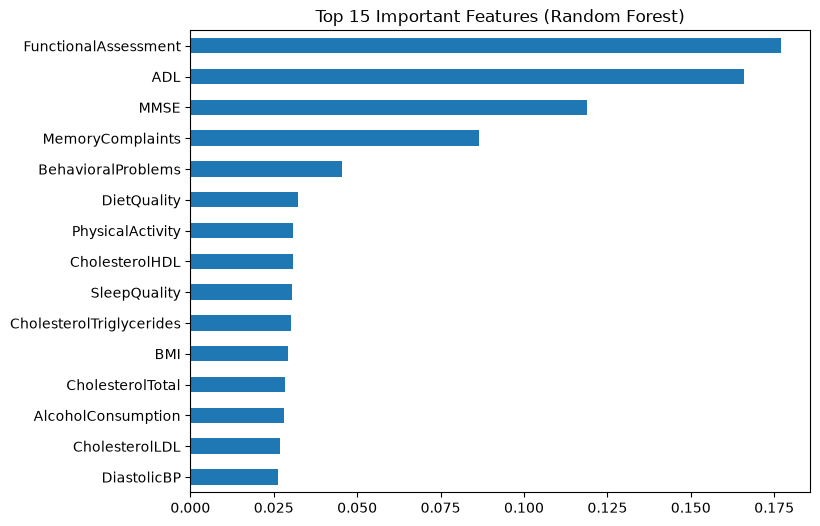

In [19]:
plt.figure(figsize=(8, 6))
importance.head(15).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Top 15 Important Features (Random Forest)")
plt.show()

In [20]:
from sklearn.feature_selection import SelectKBest, f_classif

skb = SelectKBest(f_classif, k=15)
skb.fit(X_train, y_train)
selected = X.columns[skb.get_support()]
print(list(selected))

['EducationLevel', 'BMI', 'SleepQuality', 'FamilyHistoryAlzheimers', 'CardiovascularDisease', 'Diabetes', 'SystolicBP', 'CholesterolHDL', 'CholesterolTriglycerides', 'MMSE', 'FunctionalAssessment', 'MemoryComplaints', 'BehavioralProblems', 'ADL', 'PersonalityChanges']


In [21]:
top_features = list(importance.head(15).index)

X_train_top = X_train[top_features]
X_test_top = X_test[top_features]

scaler_top = StandardScaler()
X_train_top_s = scaler_top.fit_transform(X_train_top)
X_test_top_s = scaler_top.transform(X_test_top)

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [23]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

In [24]:
results = []

for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    prob = model.predict_proba(X_test_s)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).round(3)
results_df

C:\Users\Administrator\Desktop\alzheimer_project\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
5,Gradient Boosting,0.947,0.927,0.921,0.924,0.946
4,Random Forest,0.944,0.944,0.895,0.919,0.940
3,Decision Tree,0.900,0.847,0.875,0.861,0.894
2,SVM,0.835,0.791,0.724,0.756,0.896
0,Logistic Regression,0.816,0.742,0.737,0.739,0.885
1,KNN,0.707,0.633,0.408,0.496,0.738


In [25]:
from sklearn.base import clone

results_top = []

for name, model in models.items():
    m = clone(model)                      # a fresh, untrained copy
    m.fit(X_train_top_s, y_train)
    pred = m.predict(X_test_top_s)
    prob = m.predict_proba(X_test_top_s)[:, 1]
    results_top.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

results_top_df = pd.DataFrame(results_top).sort_values("F1", ascending=False).round(3)
results_top_df

C:\Users\Administrator\Desktop\alzheimer_project\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
4,Random Forest,0.951,0.946,0.914,0.930,0.943
5,Gradient Boosting,0.944,0.921,0.921,0.921,0.950
3,Decision Tree,0.914,0.866,0.895,0.880,0.910
2,SVM,0.844,0.801,0.743,0.771,0.913
0,Logistic Regression,0.819,0.743,0.743,0.743,0.888
1,KNN,0.793,0.709,0.704,0.706,0.844


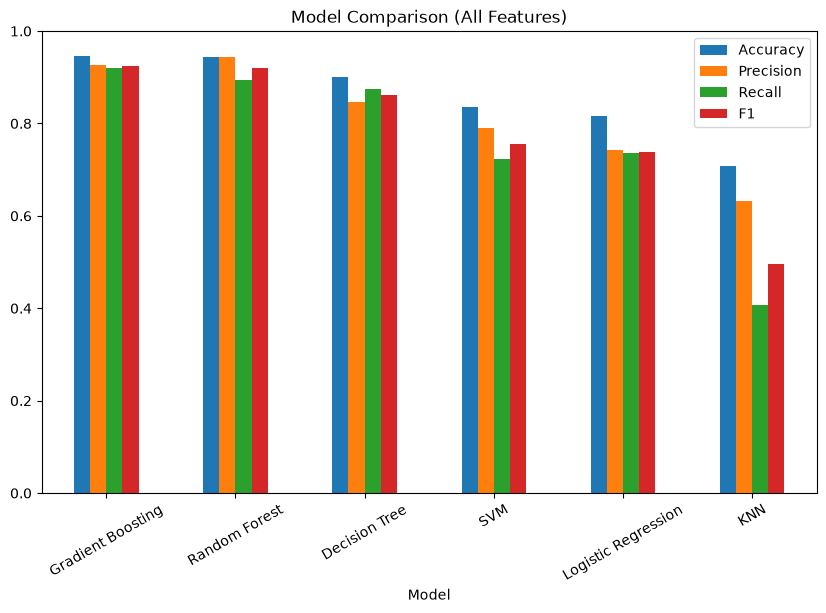

In [26]:
results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(10, 6))
plt.title("Model Comparison (All Features)")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.show()

In [27]:
print(X_train_s.shape, X_test_s.shape)
results_df

(1719, 32) (430, 32)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
5,Gradient Boosting,0.947,0.927,0.921,0.924,0.946
4,Random Forest,0.944,0.944,0.895,0.919,0.940
3,Decision Tree,0.900,0.847,0.875,0.861,0.894
2,SVM,0.835,0.791,0.724,0.756,0.896
0,Logistic Regression,0.816,0.742,0.737,0.739,0.885
1,KNN,0.707,0.633,0.408,0.496,0.738


In [28]:
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]
print("Best model:", best_name)
print(results_df.iloc[0])

Best model: Gradient Boosting
Model        Gradient Boosting
Accuracy                 0.947
Precision                0.927
Recall                   0.921
F1                       0.924
ROC-AUC                  0.946
Name: 5, dtype: object


In [30]:
from sklearn.metrics import classification_report, confusion_matrix

pred = best_model.predict(X_test_s)
print(classification_report(y_test, pred, target_names=["No Alzheimer's", "Alzheimer's"]))

                precision    recall  f1-score   support

No Alzheimer's       0.96      0.96      0.96       278
   Alzheimer's       0.93      0.92      0.92       152

      accuracy                           0.95       430
     macro avg       0.94      0.94      0.94       430
  weighted avg       0.95      0.95      0.95       430



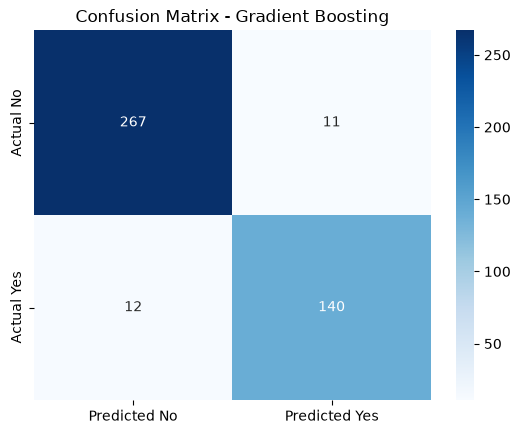

In [31]:
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted No", "Predicted Yes"],
            yticklabels=["Actual No", "Actual Yes"])
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

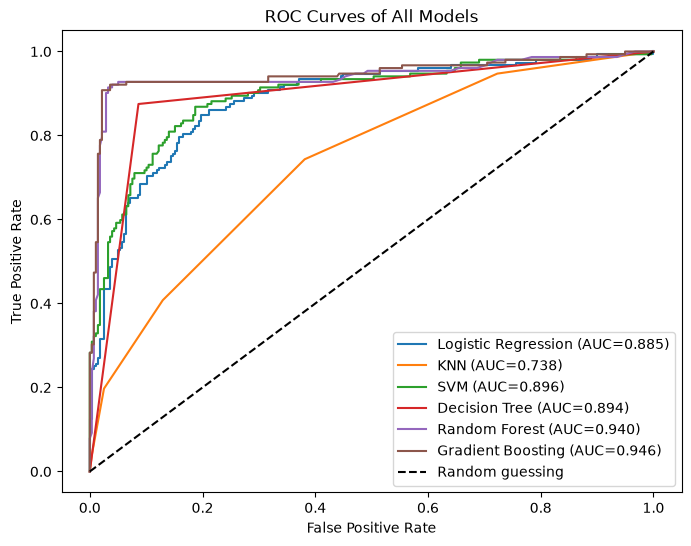

In [32]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))
for name, model in models.items():
    prob = model.predict_proba(X_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves of All Models")
plt.legend()
plt.show()

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from sklearn.base import clone

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", clone(best_model)),
])

cv_f1 = cross_val_score(pipe, X, y, cv=5, scoring="f1")
print("F1 for each fold:", cv_f1.round(3))
print("Average F1:", cv_f1.mean().round(3), "+/-", cv_f1.std().round(3))

F1 for each fold: [0.968 0.964 0.974 0.981 0.71 ]
Average F1: 0.919 +/- 0.105


In [34]:
train_f1 = f1_score(y_train, best_model.predict(X_train_s))
test_f1 = f1_score(y_test, best_model.predict(X_test_s))
print("Train F1:", round(train_f1, 3))
print("Test F1:", round(test_f1, 3))

Train F1: 0.953
Test F1: 0.924


In [35]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [2, 3]},
    cv=5, scoring="f1", n_jobs=-1
)
grid.fit(X_train_s, y_train)

print("Best settings:", grid.best_params_)
print("Best CV F1:", round(grid.best_score_, 3))
print("Test F1:", round(f1_score(y_test, grid.best_estimator_.predict(X_test_s)), 3))

Best settings: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}
Best CV F1: 0.935
Test F1: 0.934


<h2> Saving the best model

In [37]:
final_model = best_model
final_name = best_name

In [38]:
print("Final model:", final_name)
print("Test F1:", round(f1_score(y_test, final_model.predict(X_test_s)), 3))

Final model: Gradient Boosting
Test F1: 0.924


In [39]:
import joblib

joblib.dump(final_model, "../models/best_model.pkl")
joblib.dump(scaler, "../models/scaler.pkl")
joblib.dump(list(X.columns), "../models/features.pkl")

results_df.to_csv("../models/model_comparison.csv", index=False)
print("All files saved!")

All files saved!


In [40]:
loaded_model = joblib.load("../models/best_model.pkl")
loaded_scaler = joblib.load("../models/scaler.pkl")
loaded_features = joblib.load("../models/features.pkl")

# Take one real patient from the test set
sample = X_test.iloc[[0]][loaded_features]
sample_scaled = loaded_scaler.transform(sample)

prob = loaded_model.predict_proba(sample_scaled)[0][1]
print("Predicted risk:", round(prob * 100, 1), "%")
print("Actual diagnosis:", y_test.iloc[0])

Predicted risk: 92.5 %
Actual diagnosis: 1
